<Axes: >

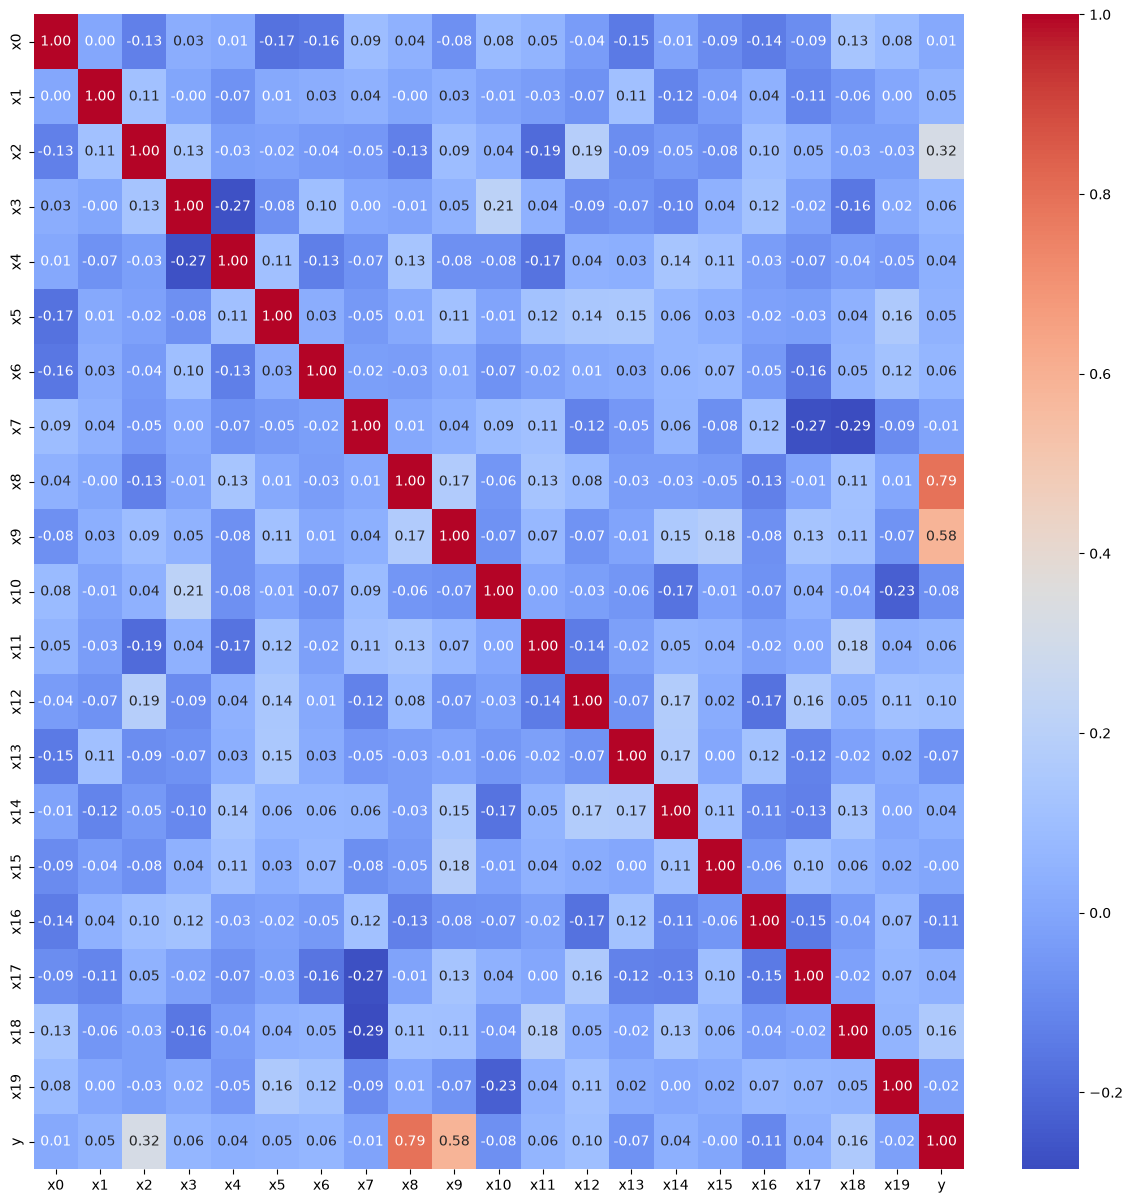

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.model_selection as sk


df = pd.read_csv(filepath_or_buffer="./data4.csv")
#df.info()
#sns.pairplot(df) #48s na pc i chuja widac 
#plt.show()

cor = df.corr()
plt.figure(figsize=(15, 15))
sns.heatmap(cor, annot=True, cmap="coolwarm", fmt=".2f")


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

X = df.drop(columns=["y"])
y = df["y"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=2137)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=2137)

model_LR = LinearRegression()
model_LR.fit(X_train, y_train)
mse_LR = mean_squared_error(y_test, model_LR.predict(X_test))

lambdas = [0.1, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0]
best_lambda = None
best_mse = float('inf')

for l in lambdas:
    model_testowy = Ridge(alpha=l).fit(X_train, y_train)
    mse_testowe = mean_squared_error(y_val, model_testowy.predict(X_val))
    if best_lambda is None or mse_testowe < best_mse:
        best_lambda = l
        best_mse = mse_testowe

model_ridge = Ridge(alpha=best_lambda).fit(X_train, y_train)
mse_ridge_test = mean_squared_error(y_test, model_ridge.predict(X_test))

print("MSE dla modelu regresji liniowej:", mse_LR)
print("MSE dla modelu Ridge Regression:", mse_ridge_test)

print("\nWspółczynniki Linear Regression:\n", model_LR.coef_)
print(f"\nWspółczynniki Ridge (lambda={best_lambda}):\n", model_ridge.coef_)

MSE dla modelu regresji liniowej: 167.29066785886272
MSE dla modelu Ridge Regression: 150.4453158445502

Współczynniki Linear Regression:
 [ 8.76810422e+00 -9.58007643e-01  4.04676620e+01 -1.58187479e+00
 -4.10615629e+00  4.11300007e+00  1.06003953e+01 -2.41400828e+00
  8.09250806e+01  3.52579814e+01 -8.10649086e-01 -2.85294815e+00
 -3.02087581e+00 -1.10121020e+00  2.94284152e+00 -6.19194580e-02
 -1.37346862e+00  1.13247918e+00  6.83219242e-01 -2.86643320e+00]

Współczynniki Ridge (lambda=1.0):
 [ 7.84327788 -0.81545767 38.91477334 -1.03743786 -3.22114252  3.48154507
 10.25178713 -1.90958641 79.00472162 35.26249165 -1.14896364 -2.41505334
 -2.29102536 -1.28509676  2.70876285 -0.49540241 -1.33484485  0.99400663
  0.82124443 -2.61027018]
